In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.durability import build_durability_table, player_durability_history

df_adj = pd.read_parquet("../data/processed/atp_long_with_elo_2021_2026.parquet")

# 1. Ranking completo de Durabilidad vs. Techo en 2026 (cohorte con al menos 30 partidos)
dur_2026 = build_durability_table(df_adj, season=2026, min_matches=30)

cols_show = [
    "player_name", "matches", "hours_on_court", "big_title_avail_pct",
    "peak_elo", "dominance_ratio", "pts_per_big_title", "net_pts_above_avg"
]
display(dur_2026.head(12)[cols_show].round(2))

# 2. Histórico de durabilidad de Zverev (2021-2026) para ver su consistencia física
zverev_hist = player_durability_history(df_adj, "Alexander Zverev")
display(zverev_hist[["season"] + cols_show[1:]].round(2))

,player_name,matches,hours_on_court,big_title_avail_pct,peak_elo,dominance_ratio,pts_per_big_title,net_pts_above_avg
0,Alexander Zverev,86.0,189.85,100.00,2044.81,1.28,662.31,604.46
1,Jannik Sinner,47.0,90.07,61.54,2291.38,1.49,981.25,474.03
2,Carlos Alcaraz,52.0,103.80,53.85,2245.26,1.29,650.00,438.71
3,Daniil Medvedev,75.0,134.22,100.00,1942.97,1.20,174.62,365.09
4,Tommy Paul,70.0,140.40,92.31,1912.32,1.16,130.00,325.06
5,Taylor Fritz,68.0,129.13,76.92,1942.13,1.20,132.00,311.72
6,Ben Shelton,66.0,145.40,92.31,1956.57,1.12,295.83,266.99
7,Rafael Jodar,66.0,126.42,92.31,2006.20,1.09,185.00,228.08
8,Alex de Minaur,66.0,126.42,100.00,1981.07,1.11,110.00,222.82
9,Felix Auger-Aliassime,53.0,111.47,84.62,1931.34,1.16,133.64,209.75


,season,matches,hours_on_court,big_title_avail_pct,peak_elo,dominance_ratio,pts_per_big_title,net_pts_above_avg
0,2021,67.0,133.15,91.67,2063.70,1.27,464.55,464.98
1,2022,37.0,58.12,58.33,2087.59,1.16,380.00,184.55
2,2023,80.0,166.73,100.00,2023.16,1.13,178.46,281.35
3,2024,88.0,192.18,100.00,2011.17,1.28,476.92,613.92
4,2025,80.0,159.77,100.00,2038.69,1.18,270.77,360.38
5,2026,86.0,189.85,100.00,2044.81,1.28,662.31,604.46


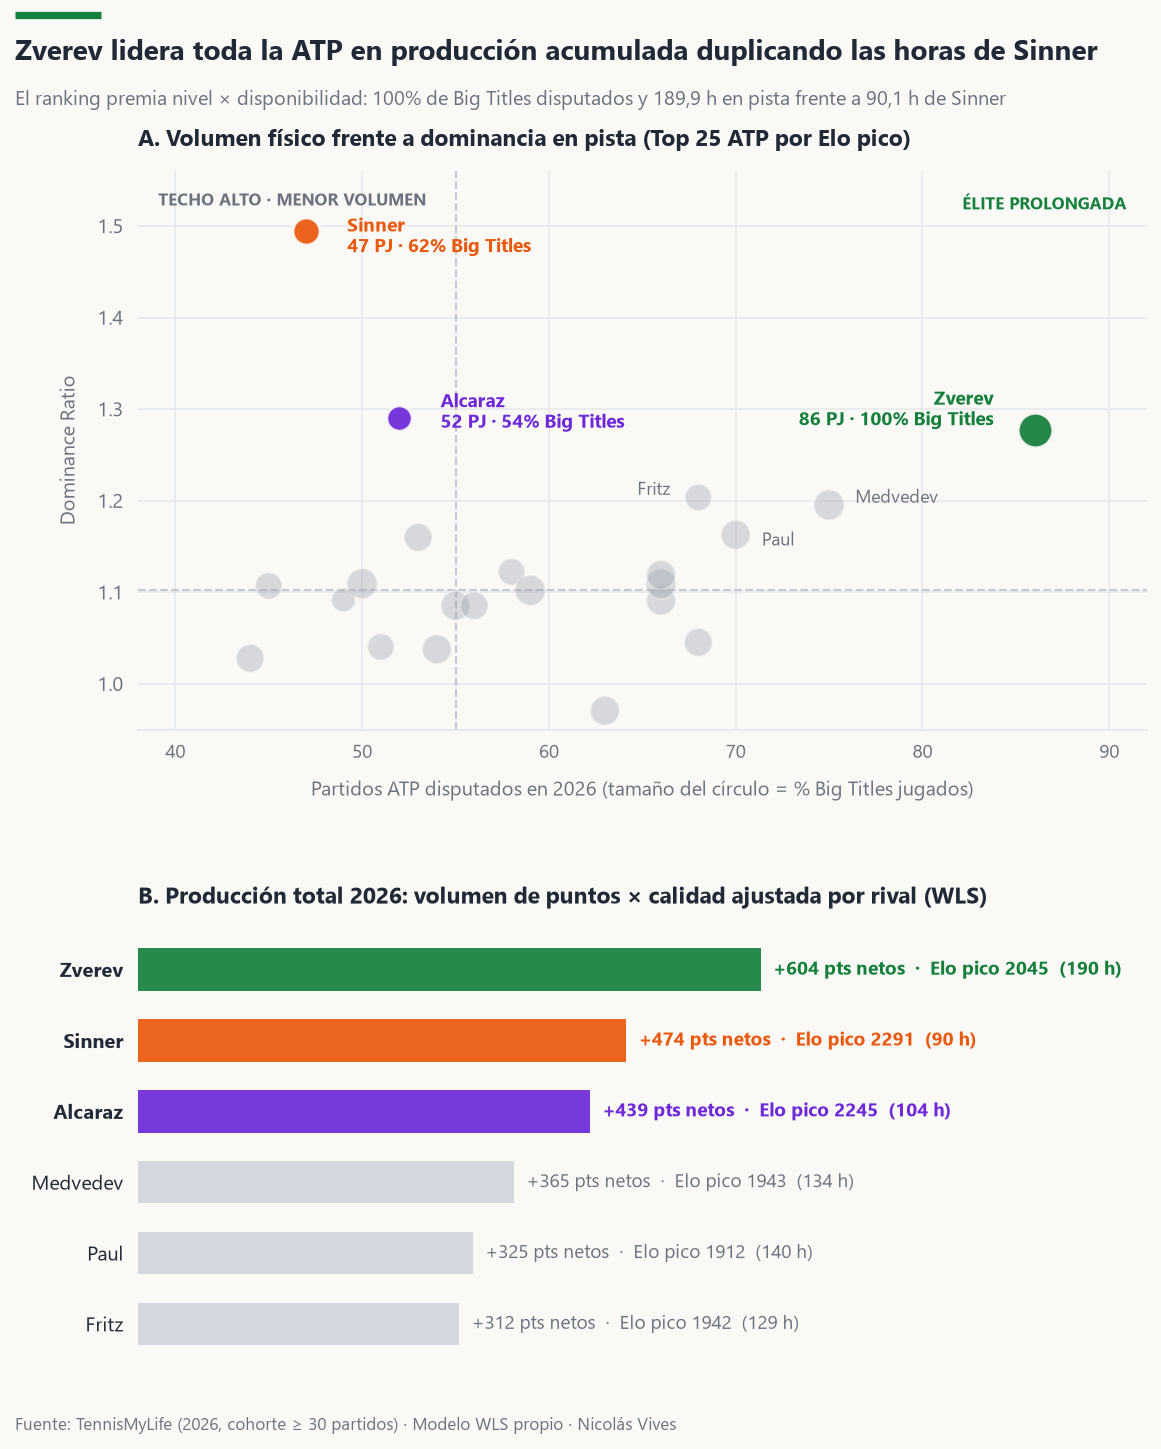

In [4]:
from src.viz import PALETTE, apply_editorial_style, add_editorial_chrome, save_figure

apply_editorial_style()

highlight = {
    "Alexander Zverev": PALETTE["zverev"],
    "Jannik Sinner": PALETTE["sinner"],
    "Carlos Alcaraz": PALETTE["alcaraz"],
}

top25 = dur_2026.sort_values("peak_elo", ascending=False).head(25).copy()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(8.2, 9.8), gridspec_kw={"height_ratios": [1.28, 1.0]}
)

# --- PANEL SUPERIOR: Partidos jugados vs. Dominance Ratio ---
ax1.spines["left"].set_visible(False)

med_x = top25["matches"].median()
med_y = top25["dominance_ratio"].median()
ax1.axvline(med_x, color=PALETTE["neutral"], linestyle="--", lw=1.0, alpha=0.55, zorder=1)
ax1.axhline(med_y, color=PALETTE["neutral"], linestyle="--", lw=1.0, alpha=0.55, zorder=1)

others = top25[~top25["player_name"].isin(highlight.keys())]
ax1.scatter(
    others["matches"],
    others["dominance_ratio"],
    s=others["big_title_avail_pct"] * 2.1,
    color=PALETTE["neutral"],
    alpha=0.38,
    edgecolors=PALETTE["bg"],
    lw=0.9,
    zorder=2,
)

# Etiquetar Top 3 fuera del Big 3 sin colisiones
extra_offsets = {
    "Daniil Medvedev": (1.4, 0.008, "left"),
    "Tommy Paul": (1.4, -0.006, "left"),
    "Taylor Fritz": (-1.5, 0.008, "right"),
}
for row in others.sort_values("net_pts_above_avg", ascending=False).head(3).itertuples(index=False):
    dx, dy, ha = extra_offsets.get(row.player_name, (1.2, 0.0, "left"))
    ax1.text(
        row.matches + dx, row.dominance_ratio + dy,
        row.player_name.split()[-1],
        fontsize=8.5, color=PALETTE["muted"], va="center", ha=ha,
    )

# Resaltar Big 3 con etiquetas limpias
big3_offsets = {
    "Jannik Sinner": (2.2, -0.006, "left"),
    "Carlos Alcaraz": (2.2, 0.006, "left"),
    "Alexander Zverev": (-2.2, 0.022, "right"),
}
for name, color in highlight.items():
    sub = top25[top25["player_name"] == name]
    if sub.empty:
        continue
    row = sub.iloc[0]
    ax1.scatter(
        row["matches"],
        row["dominance_ratio"],
        s=row["big_title_avail_pct"] * 2.8,
        color=color,
        alpha=0.93,
        edgecolors=PALETTE["bg"],
        lw=1.5,
        zorder=4,
    )
    dx, dy, ha = big3_offsets[name]
    ax1.text(
        row["matches"] + dx,
        row["dominance_ratio"] + dy,
        f"{name.split()[-1]}\n{int(row['matches'])} PJ · {row['big_title_avail_pct']:.0f}% Big Titles",
        color=color, fontsize=9.2, fontweight="bold", ha=ha, va="center",
    )

# Etiquetas sutiles de cuadrantes
ax1.text(0.02, 0.96, "TECHO ALTO · MENOR VOLUMEN", transform=ax1.transAxes, fontsize=8.0, color=PALETTE["muted"], fontweight="bold", va="top")
ax1.text(0.98, 0.96, "ÉLITE PROLONGADA", transform=ax1.transAxes, fontsize=8.0, color=PALETTE["zverev"], fontweight="bold", ha="right", va="top")

ax1.set_xlim(38, 92)
ax1.set_ylim(0.95, 1.56)
ax1.set_xlabel("Partidos ATP disputados en 2026 (tamaño del círculo = % Big Titles jugados)")
ax1.set_ylabel("Dominance Ratio")
ax1.set_title(
    "A. Volumen físico frente a dominancia en pista (Top 25 ATP por Elo pico)",
    fontsize=10.8, fontweight="bold", color=PALETTE["text"], loc="left", pad=12,
)

# --- PANEL INFERIOR: Valor acumulado de temporada ("Tennis WAR") ---
ax2.spines["left"].set_visible(False)
ax2.spines["bottom"].set_visible(False)
ax2.grid(visible=False)
ax2.set_xticks([])

top6 = dur_2026.head(6).iloc[::-1].reset_index(drop=True)
bar_colors = [highlight.get(p, PALETTE["bar_muted"]) for p in top6["player_name"]]

bars = ax2.barh(
    top6["player_name"].apply(lambda s: s.split()[-1]),
    top6["net_pts_above_avg"],
    height=0.60,
    color=bar_colors,
    alpha=0.92,
)

max_val = top6["net_pts_above_avg"].max()
for bar, row in zip(bars, top6.itertuples(index=False)):
    w = bar.get_width()
    is_big3 = row.player_name in highlight
    ax2.text(
        w + max_val * 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"+{w:.0f} pts netos  ·  Elo pico {row.peak_elo:.0f}  ({row.hours_on_court:.0f} h)",
        va="center", ha="left", fontsize=9.0,
        fontweight="bold" if is_big3 else "normal",
        color=highlight.get(row.player_name, PALETTE["muted"]),
    )

ax2.set_xlim(0, max_val * 1.62)
ax2.tick_params(axis="y", colors=PALETTE["text"])
for tick_label, name in zip(ax2.get_yticklabels(), top6["player_name"]):
    if name in highlight:
        tick_label.set_fontweight("bold")

ax2.set_title(
    "B. Producción total 2026: volumen de puntos × calidad ajustada por rival (WLS)",
    fontsize=10.8, fontweight="bold", color=PALETTE["text"], loc="left", pad=12,
)

add_editorial_chrome(
    fig,
    title="Zverev lidera toda la ATP en producción acumulada duplicando las horas de Sinner",
    subtitle="El ranking premia nivel × disponibilidad: 100% de Big Titles disputados y 189,9 h en pista frente a 90,1 h de Sinner",
    source="Fuente: TennisMyLife (2026, cohorte ≥ 30 partidos) · Modelo WLS propio · Nicolás Vives",
    accent_color=PALETTE["zverev"],
    left=0.14,
    right=0.96,
    top_pad_in=1.22,
    bottom_pad_in=0.62,
    hspace=0.40,
)

save_figure(fig, "04_durability_vs_ceiling_2026")
plt.show()